# Pais-Uhlenbeck con interaccion cuartica

Hamiltoniano truncado a la base de Fock par `|2k, 2l>`:

$$H' = \hbar\omega_1 N_a - \hbar\omega_2 N_b + \lambda Q_1^2 Q_2^2.$$

El estado inicial es `|0,0>`. La evolucion de abajo es exacta para el corte `K`, no una prueba de estabilidad en dimension infinita.

El orquestador esta en `src/pu_q/orquestador.py`. Las clases del modelo estan en `src/pu_q/clases/`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

In [2]:
import numpy as np
from pu_q.clases import EvolucionUnitaria, VerificadorMatriz4x4
from pu_q.orquestador import Orquestador

## Comprobacion de la matriz 4x4

Para `K=1` la base es `|0,0>, |2,0>, |0,2>, |2,2>`.

In [3]:
sistema = VerificadorMatriz4x4().verificar(omega1=1.0, omega2=2.0, lam=0.2, hbar=1.0)

Comprobacion de matriz 4x4: CORRECTA
Orden de la base: |0,0>, |2,0>, |0,2>, |2,2>
[[ 0.025     0.035355  0.035355  0.05    ]
 [ 0.035355  2.125     0.05      0.176777]
 [ 0.035355  0.05     -3.875     0.176777]
 [ 0.05      0.176777  0.176777 -1.375   ]]


## Un corte pequeno

`EvolucionUnitaria` construye `H_K` y devuelve `<N>`, la varianza, la probabilidad de vacio y la masa en el borde.

In [4]:
K = 4
tiempos = np.linspace(0.0, 2.0, 41)
datos = EvolucionUnitaria(K, omega1=1.0, omega2=2.0, lam=0.2, hbar=1.0).evolucionar(tiempos)
{
    "dimension": datos["dimension"],
    "E0": datos["E0"],
    "max|norma-1|": float(np.max(np.abs(datos["norma"] - 1.0))),
    "N(t_final)": float(datos["N"][-1]),
}

{'dimension': 25,
 'E0': 0.025,
 'max|norma-1|': 1.7763568394002505e-15,
 'N(t_final)': 0.023018112401078837}

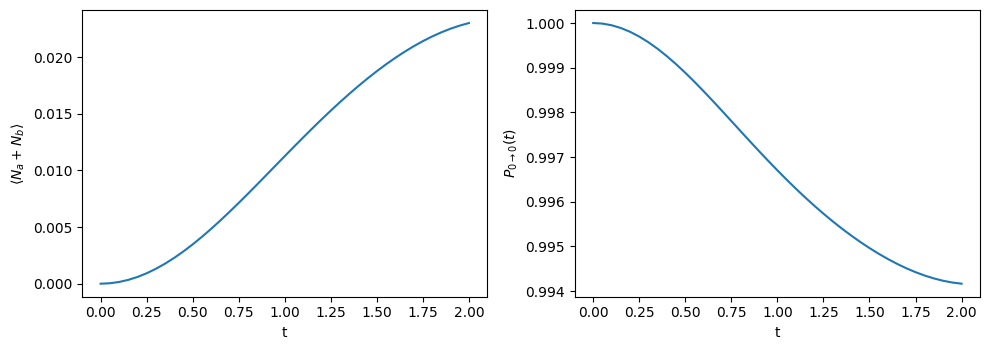

In [5]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
ejes[0].plot(datos["t"], datos["N"])
ejes[0].set_xlabel("t")
ejes[0].set_ylabel(r"$\langle N_a+N_b\rangle$")
ejes[1].plot(datos["t"], datos["P0"])
ejes[1].set_xlabel("t")
ejes[1].set_ylabel(r"$P_{0\to 0}(t)$")
fig.tight_layout()

## Barrido corto de cortes

`Orquestador(..., quick=True)` usa `K = 1, 4, 8`, `tmax = 2` y escribe CSV y PNG en `resultados_notebook/`.

In [6]:
Orquestador(
    omega2="2",
    outdir=RAIZ / "resultados_notebook",
).ejecutar()

Comprobacion de matriz 4x4: CORRECTA
Orden de la base: |0,0>, |2,0>, |0,2>, |2,2>
[[ 0.025     0.035355  0.035355  0.05    ]
 [ 0.035355  2.125     0.05      0.176777]
 [ 0.035355  0.05     -3.875     0.176777]
 [ 0.05      0.176777  0.176777 -1.375   ]]

Simulando omega1=1, omega2=2, lambda=0.2, hbar=1
  Calculando K=12, dimension=169...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_12.csv
  Calculando K=40, dimension=1681...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_40.csv
  Calculando K=60, dimension=3721...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_60.csv
  Calculando K=80, dimension=6561...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_80.csv
  Calculando K=100, dimension=10201...
  Archivo: /home/thebigmonster/Github/stability-higher-order/resultados_notebook/pu_omega2_2_K_100.cs